# Insurance Risk Scoring Using Deep Learning

This Google Colab project builds an end-to-end **Insurance Risk Scoring System** using a Deep Neural Network (DNN).

### What this notebook covers
1. Generate a realistic synthetic insurance dataset
2. Data cleaning and exploratory data analysis
3. Feature engineering
4. Train/test preprocessing
5. Deep Learning model with TensorFlow/Keras
6. Model evaluation
7. Convert claim probability into a 0–100 risk score
8. Low / Medium / High risk classification
9. SHAP-based explainability
10. Save the trained model and preprocessing objects
Insurance Risk Scoring System Using Deep Neural Network

This project develops an end-to-end Insurance Risk Scoring System using a Deep Neural Network (DNN) to predict the risk level associated with an insurance applicant. The system uses customer and policy-related information such as age, income, occupation, health/lifestyle factors, policy details, claim history, and other relevant attributes to identify the likelihood of an applicant being a high-risk or low-risk customer.

The complete project is implemented in Google Colab using Python, covering the entire machine learning workflow from data preprocessing to model evaluation and risk prediction.

🔹 Project Objective

The primary objective is to build an intelligent risk assessment model that can:

Analyze historical insurance/customer data.
Identify important factors contributing to insurance risk.
Preprocess and transform raw data into a format suitable for deep learning.
Train a Deep Neural Network (DNN) for risk prediction.
Classify applicants into different risk categories.
Evaluate the performance of the trained model using appropriate classification metrics.
Generate risk predictions for new insurance applicants.
> **Note:** The dataset is synthetic and intended for learning/portfolio purposes. A real insurance system requires domain validation, calibration, fairness testing, privacy controls, and applicable regulatory review.


In [ ]:
# Install required packages
!pip -q install shap joblib


In [ ]:
# Import libraries
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import shap

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


## 1. Generate a Synthetic Insurance Dataset

The target variable is `claim_occurred`:

- `0` = No claim
- `1` = Claim

The data-generation process intentionally makes claim probability depend on multiple risk factors so that the neural network has meaningful patterns to learn.


In [ ]:
# Generate synthetic insurance customer data
N = 5000
rng = np.random.default_rng(SEED)

age = rng.integers(18, 81, N)
gender = rng.choice(["Male", "Female"], N)
bmi = np.clip(rng.normal(27, 5, N), 16, 45)
smoker = rng.choice(["No", "Yes"], N, p=[0.78, 0.22])
annual_income = np.clip(rng.lognormal(mean=np.log(65000), sigma=0.45, size=N), 18000, 250000)
dependents = rng.integers(0, 5, N)
previous_claims = rng.poisson(0.8, N)
hospital_visits = rng.poisson(2.0, N)
policy_duration = rng.integers(1, 16, N)
chronic_condition = rng.choice(["No", "Yes"], N, p=[0.72, 0.28])
exercise_frequency = rng.choice(
    ["Low", "Medium", "High"], N, p=[0.30, 0.45, 0.25]
)
alcohol_consumption = rng.choice(
    ["Low", "Medium", "High"], N, p=[0.50, 0.35, 0.15]
)
region = rng.choice(
    ["North", "South", "East", "West"], N
)

# Feature engineering used in the synthetic target-generation mechanism
claim_frequency = previous_claims / np.maximum(policy_duration, 1)
hospitalization_rate = hospital_visits / np.maximum(policy_duration, 1)

smoker_num = (smoker == "Yes").astype(int)
chronic_num = (chronic_condition == "Yes").astype(int)

exercise_risk = pd.Series(exercise_frequency).map(
    {"Low": 0.45, "Medium": 0.15, "High": -0.15}
).to_numpy()

alcohol_risk = pd.Series(alcohol_consumption).map(
    {"Low": 0.00, "Medium": 0.18, "High": 0.38}
).to_numpy()

# Nonlinear risk signal
logit = (
    -3.1
    + 0.025 * (age - 40)
    + 0.075 * (bmi - 25)
    + 1.15 * smoker_num
    + 0.32 * dependents
    + 0.42 * previous_claims
    + 0.20 * hospital_visits
    - 0.025 * (policy_duration - 5)
    + 0.95 * chronic_num
    + exercise_risk
    + alcohol_risk
    + 0.55 * np.maximum(bmi - 30, 0)
    + 0.35 * claim_frequency
)

claim_probability = 1 / (1 + np.exp(-logit))
claim_occurred = rng.binomial(1, claim_probability)

# Synthetic claim amount: zero for no claim, positive for claims
base_claim = (
    1500
    + 45 * age
    + 1800 * smoker_num
    + 2200 * chronic_num
    + 500 * previous_claims
    + 350 * hospital_visits
    + rng.normal(0, 1000, N)
)
claim_amount = np.where(
    claim_occurred == 1,
    np.maximum(base_claim, 500),
    0
)

df = pd.DataFrame({
    "age": age,
    "gender": gender,
    "bmi": bmi,
    "smoker": smoker,
    "annual_income": annual_income.round(2),
    "dependents": dependents,
    "previous_claims": previous_claims,
    "hospital_visits": hospital_visits,
    "policy_duration": policy_duration,
    "chronic_condition": chronic_condition,
    "exercise_frequency": exercise_frequency,
    "alcohol_consumption": alcohol_consumption,
    "region": region,
    "claim_amount": claim_amount.round(2),
    "claim_occurred": claim_occurred
})

df.head()
df


,age,gender,bmi,smoker,annual_income,dependents,previous_claims,hospital_visits,policy_duration,chronic_condition,exercise_frequency,alcohol_consumption,region,claim_amount,claim_occurred
0,23,Male,21.505377,No,28880.50,3,0,3,5,Yes,Medium,Medium,East,5577.72,1
1,66,Male,24.293428,Yes,71380.25,3,0,3,2,No,Medium,Low,South,0.00,0
2,59,Female,28.360006,No,48918.56,0,2,4,6,Yes,High,Low,East,0.00,0
3,45,Female,23.858400,No,53133.46,3,0,2,1,No,High,Low,South,0.00,0
4,45,Female,25.608168,Yes,51519.68,1,0,1,12,Yes,High,Low,South,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,31,Male,31.127627,No,51822.84,3,1,4,14,No,Medium,Medium,East,3930.21,1
4996,65,Female,18.036166,No,48079.05,4,0,6,10,No,High,Low,East,5202.68,1
4997,69,Male,21.787705,Yes,51916.48,0,2,2,3,No,High,Low,East,0.00,0
4998,60,Female,16.678180,No,137391.13,1,1,2,3,No,Medium,Low,East,0.00,0


In [ ]:
# Basic dataset inspection
print("Shape:", df.shape)
display(df.head())
display(df.describe(include="all").T)
print("\nMissing values:")
display(df.isnull().sum())


Shape: (5000, 15)


,age,gender,bmi,smoker,annual_income,dependents,previous_claims,hospital_visits,policy_duration,chronic_condition,exercise_frequency,alcohol_consumption,region,claim_amount,claim_occurred
0,23,Male,21.505377,No,28880.50,3,0,3,5,Yes,Medium,Medium,East,5577.72,1
1,66,Male,24.293428,Yes,71380.25,3,0,3,2,No,Medium,Low,South,0.00,0
2,59,Female,28.360006,No,48918.56,0,2,4,6,Yes,High,Low,East,0.00,0
3,45,Female,23.858400,No,53133.46,3,0,2,1,No,High,Low,South,0.00,0
4,45,Female,25.608168,Yes,51519.68,1,0,1,12,Yes,High,Low,South,0.00,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,5000.0,NaN,NaN,NaN,48.9204,18.237746,18.0,33.0,49.0,65.0,80.0
gender,5000,2,Male,2531,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,5000.0,NaN,NaN,NaN,27.016048,4.980907,16.0,23.685597,26.899721,30.351598,45.0
smoker,5000,2,No,3918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income,5000.0,NaN,NaN,NaN,73023.368434,33926.139607,18000.0,48454.5425,65783.165,89881.5725,250000.0
dependents,5000.0,NaN,NaN,NaN,2.0396,1.424373,0.0,1.0,2.0,3.0,4.0
previous_claims,5000.0,NaN,NaN,NaN,0.801,0.901755,0.0,0.0,1.0,1.0,6.0
hospital_visits,5000.0,NaN,NaN,NaN,2.0164,1.42539,0.0,1.0,2.0,3.0,9.0
policy_duration,5000.0,NaN,NaN,NaN,7.9172,4.326625,1.0,4.0,8.0,12.0,15.0
chronic_condition,5000,2,No,3611,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,0
age,0
gender,0
bmi,0
smoker,0
annual_income,0
dependents,0
previous_claims,0
hospital_visits,0
policy_duration,0
chronic_condition,0


## 2. Exploratory Data Analysis

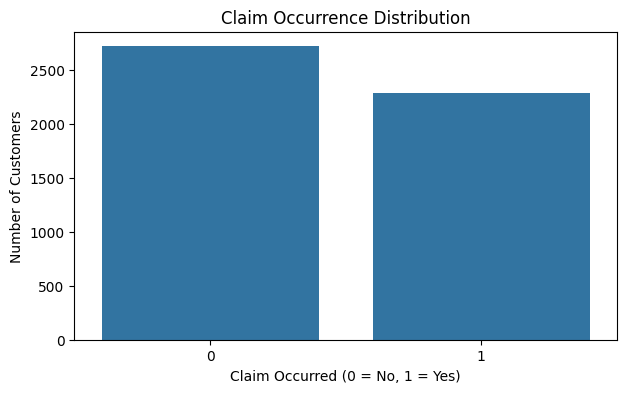

claim_occurred
0    0.5428
1    0.4572
Name: proportion, dtype: float64


In [ ]:
# Target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="claim_occurred")
plt.title("Claim Occurrence Distribution")
plt.xlabel("Claim Occurred (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

print(df["claim_occurred"].value_counts(normalize=True).rename("proportion"))


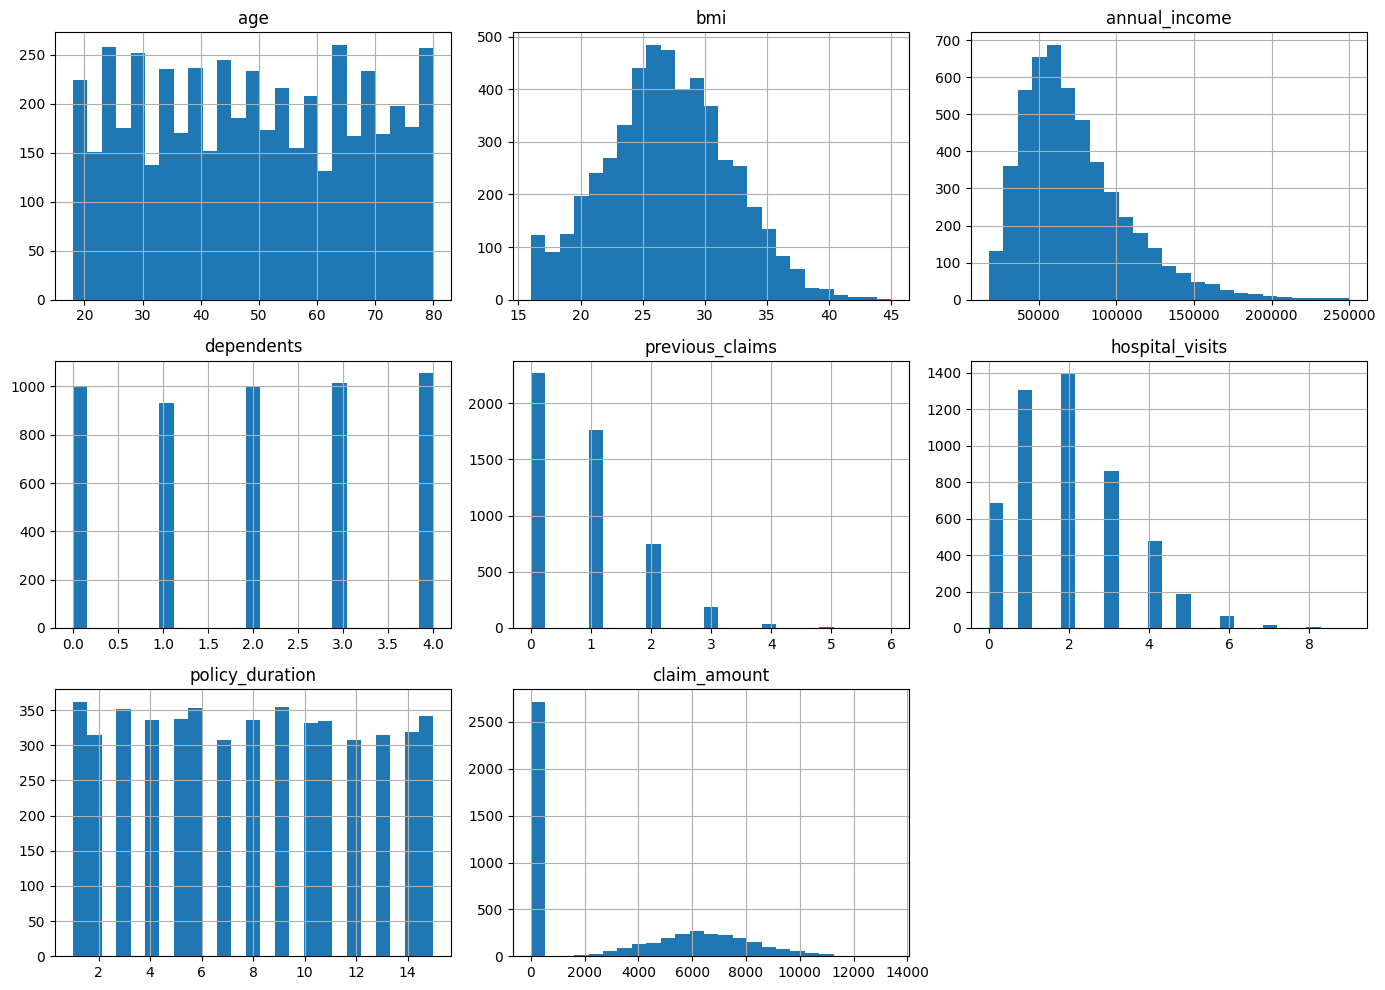

In [ ]:
# Numerical feature distributions
numeric_cols = [
    "age", "bmi", "annual_income", "dependents",
    "previous_claims", "hospital_visits", "policy_duration",
    "claim_amount"
]

df[numeric_cols].hist(figsize=(14, 10), bins=25)
plt.tight_layout()
plt.show()


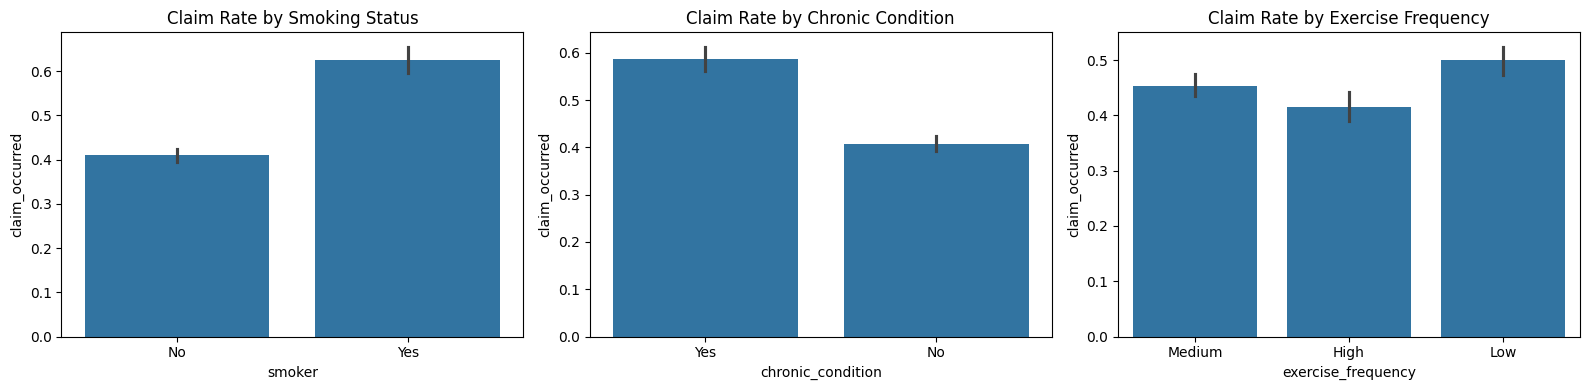

In [ ]:
# Claim rate by selected categorical variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df, x="smoker", y="claim_occurred", ax=axes[0])
axes[0].set_title("Claim Rate by Smoking Status")

sns.barplot(data=df, x="chronic_condition", y="claim_occurred", ax=axes[1])
axes[1].set_title("Claim Rate by Chronic Condition")

sns.barplot(data=df, x="exercise_frequency", y="claim_occurred", ax=axes[2])
axes[2].set_title("Claim Rate by Exercise Frequency")

plt.tight_layout()
plt.show()


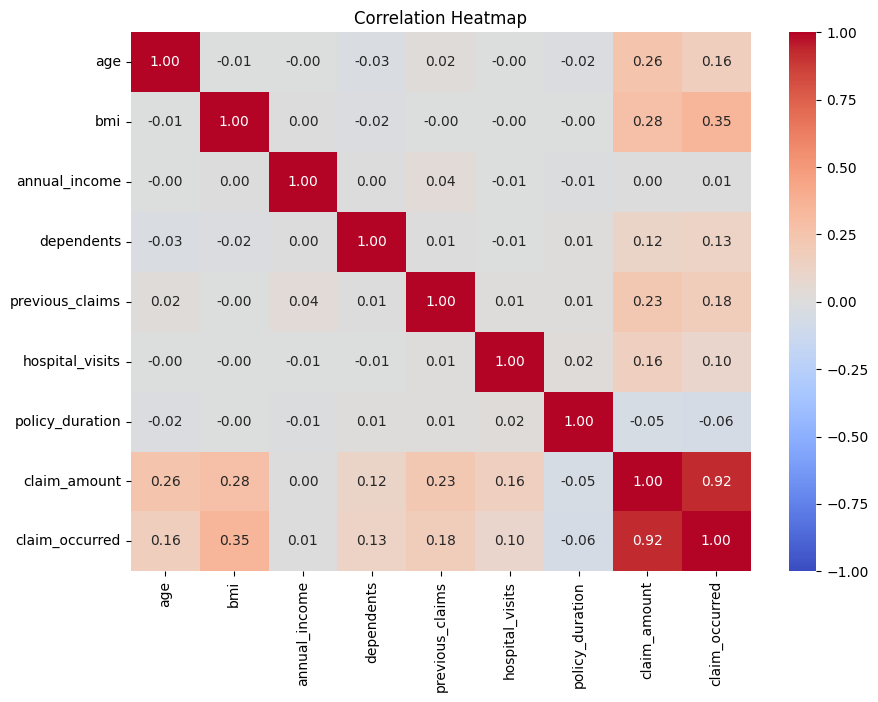

In [ ]:
# Correlation heatmap for numerical variables #MULTIVARIATE ANALYSIS
plt.figure(figsize=(10, 7))
corr = df[numeric_cols + ["claim_occurred"]].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Correlation Heatmap")
plt.show()


## 3. Feature Engineering

We create a few interpretable features:

- `claim_frequency`
- `hospitalization_rate`
- `income_per_dependent`
- `health_risk_index`


In [ ]:
# Feature engineering
df["claim_frequency"] = df["previous_claims"] / df["policy_duration"].clip(lower=1)
df["hospitalization_rate"] = df["hospital_visits"] / df["policy_duration"].clip(lower=1)
df["income_per_dependent"] = df["annual_income"] / (df["dependents"] + 1)

df["health_risk_index"] = (
    (df["bmi"] > 30).astype(int)
    + (df["smoker"] == "Yes").astype(int)
    + (df["chronic_condition"] == "Yes").astype(int)
    + (df["hospital_visits"] >= 4).astype(int)
)

display(df.head())


,age,gender,bmi,smoker,annual_income,dependents,previous_claims,hospital_visits,policy_duration,chronic_condition,exercise_frequency,alcohol_consumption,region,claim_amount,claim_occurred,claim_frequency,hospitalization_rate,income_per_dependent,health_risk_index
0,23,Male,21.505377,No,28880.50,3,0,3,5,Yes,Medium,Medium,East,5577.72,1,0.000000,0.600000,7220.1250,1
1,66,Male,24.293428,Yes,71380.25,3,0,3,2,No,Medium,Low,South,0.00,0,0.000000,1.500000,17845.0625,1
2,59,Female,28.360006,No,48918.56,0,2,4,6,Yes,High,Low,East,0.00,0,0.333333,0.666667,48918.5600,2
3,45,Female,23.858400,No,53133.46,3,0,2,1,No,High,Low,South,0.00,0,0.000000,2.000000,13283.3650,0
4,45,Female,25.608168,Yes,51519.68,1,0,1,12,Yes,High,Low,South,0.00,0,0.000000,0.083333,25759.8400,2


## 4. Prepare Data for Deep Learning

Categorical columns are one-hot encoded using `pandas.get_dummies`, and numerical features are standardized using `StandardScaler`.

The split is performed **before fitting the scaler** to avoid data leakage.


In [ ]:
# Define target and features
target = "claim_occurred"

feature_cols = [
    "age", "gender", "bmi", "smoker", "annual_income",
    "dependents", "previous_claims", "hospital_visits",
    "policy_duration", "chronic_condition",
    "exercise_frequency", "alcohol_consumption", "region",
    "claim_frequency", "hospitalization_rate",
    "income_per_dependent", "health_risk_index"
]

X = df[feature_cols].copy()
y = df[target].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_feature_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

X_train = pd.get_dummies(X_train_raw, columns=categorical_cols, dtype=float)
X_test = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=float)

# Align columns in case one split lacks a category
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

scaler = StandardScaler()

X_train[numeric_feature_cols] = scaler.fit_transform(
    X_train[numeric_feature_cols]
)

X_test[numeric_feature_cols] = scaler.transform(
    X_test[numeric_feature_cols]
)

X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

y_train = y_train.to_numpy().astype(np.float32)
y_test = y_test.to_numpy().astype(np.float32)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (4000, 27)
Testing shape: (1000, 27)


## 5. Build the Deep Neural Network

Architecture:

`Input → Dense(128) → BatchNorm → Dropout → Dense(64) → BatchNorm → Dropout → Dense(32) → Output`

The sigmoid output represents the estimated probability of a claim.


In [ ]:
# Build Deep Neural Network
model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.20),

    Dense(32, activation="relu"),
    Dropout(0.10),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,721 (57.50 KB)

 Trainable params: 14,337 (56.00 KB)

 Non-trainable params: 384 (1.50 KB)

## 6. Train the Model

In [ ]:
# Train with early stopping and learning-rate reduction
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.6425 - auc: 0.7047 - loss: 0.6513 - precision: 0.6088 - recall: 0.6408 - val_accuracy: 0.6725 - val_auc: 0.7866 - val_loss: 0.5982 - val_precision: 0.8609 - val_recall: 0.2870 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.7113 - auc: 0.7734 - loss: 0.5742 - precision: 0.7059 - recall: 0.6469 - val_accuracy: 0.7013 - val_auc: 0.7993 - val_loss: 0.5613 - val_precision: 0.8272 - val_recall: 0.3884 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.7163 - auc: 0.7871 - loss: 0.5570 - precision: 0.7140 - recall: 0.6476 - val_accuracy: 0.7237 - val_auc: 0.7975 - val_loss: 0.5426 - val_precision: 0.7768 - val_recall: 0.5043 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7262 - auc: 0.7979 - loss: 0.5410 - precision: 0.7293 - recall: 0.6516 - val_accuracy: 0.7325 - val_auc: 0.8042 - val_loss: 0.5

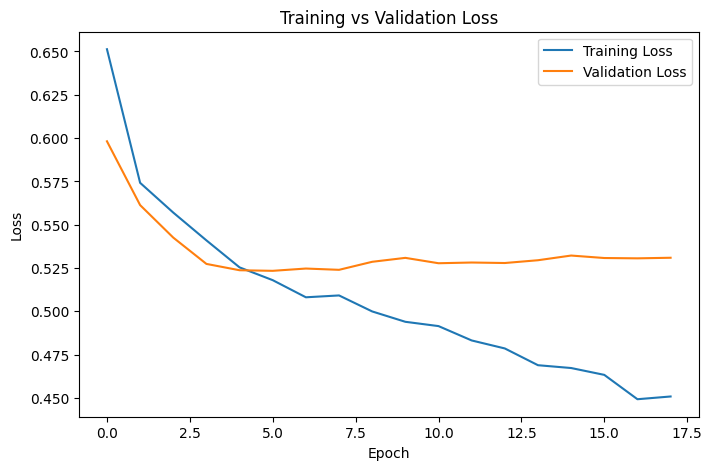

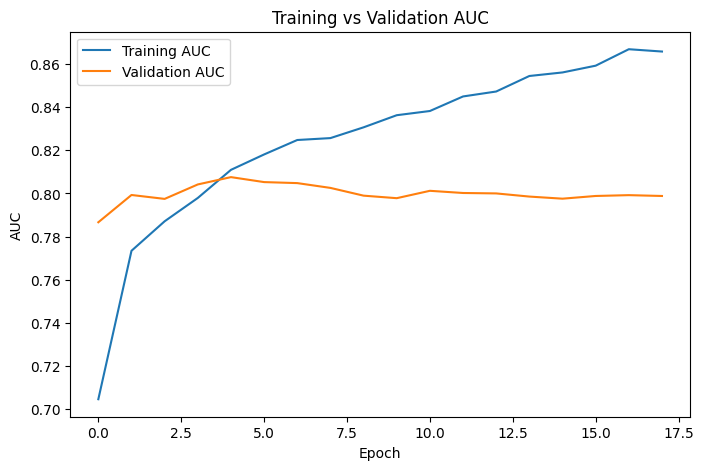

In [ ]:
# Plot training history
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["auc"], label="Training AUC")
plt.plot(history_df["val_auc"], label="Validation AUC")
plt.title("Training vs Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.show()


## 7. Evaluate the Model

In [ ]:
# Predictions
y_probability = model.predict(X_test, verbose=0).ravel()
y_prediction = (y_probability >= 0.50).astype(int)

accuracy = accuracy_score(y_test, y_prediction)
precision = precision_score(y_test, y_prediction, zero_division=0)
recall = recall_score(y_test, y_prediction, zero_division=0)
f1 = f1_score(y_test, y_prediction, zero_division=0)
auc = roc_auc_score(y_test, y_probability)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_prediction,
    target_names=["No Claim", "Claim"],
    zero_division=0
))


Accuracy : 0.7520
Precision: 0.7832
Recall   : 0.6324
F1 Score : 0.6998
ROC-AUC  : 0.8351

Classification Report:
              precision    recall  f1-score   support

    No Claim       0.73      0.85      0.79       543
       Claim       0.78      0.63      0.70       457

    accuracy                           0.75      1000
   macro avg       0.76      0.74      0.74      1000
weighted avg       0.76      0.75      0.75      1000



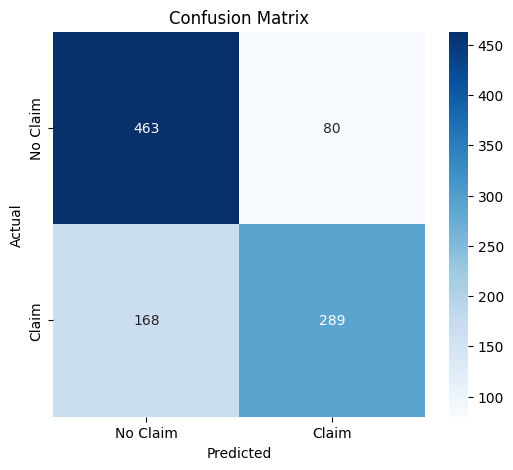

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_prediction)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Claim", "Claim"],
    yticklabels=["No Claim", "Claim"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


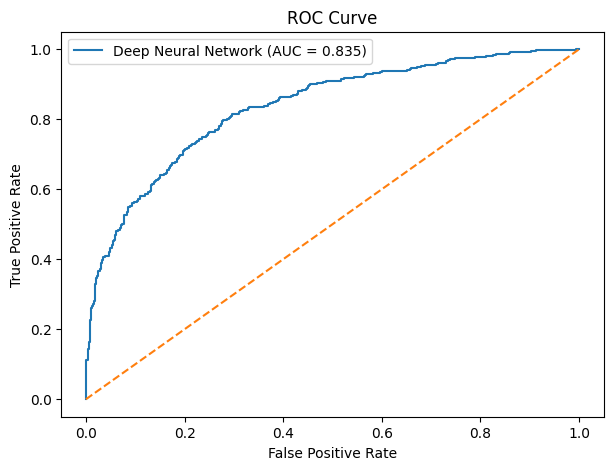

In [ ]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Deep Neural Network (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


## 8. Convert Claim Probability into an Insurance Risk Score

For this educational project:

- **0–30** → Low Risk
- **31–60** → Medium Risk
- **61–100** → High Risk

The score is derived from the model's predicted claim probability.


In [ ]:
def risk_category(score):
    if score <= 30:
        return "Low Risk"
    elif score <= 60:
        return "Medium Risk"
    return "High Risk"

risk_scores = y_probability * 100
risk_categories = np.array([risk_category(s) for s in risk_scores])

risk_results = X_test_raw.reset_index(drop=True).copy()
risk_results["actual_claim"] = y_test.astype(int)
risk_results["claim_probability"] = y_probability
risk_results["risk_score"] = risk_scores
risk_results["risk_category"] = risk_categories

display(
    risk_results[
        [
            "age", "bmi", "smoker", "previous_claims",
            "hospital_visits", "claim_probability",
            "risk_score", "risk_category"
        ]
    ].head(15)
)


,age,bmi,smoker,previous_claims,hospital_visits,claim_probability,risk_score,risk_category
0,19,29.105067,No,1,5,0.074060,7.406045,Low Risk
1,65,24.678322,No,1,6,0.546100,54.609985,Medium Risk
2,33,17.707560,No,1,2,0.118358,11.835818,Low Risk
3,24,34.580126,Yes,0,0,0.853164,85.316422,High Risk
4,31,30.477762,Yes,0,3,0.678589,67.858871,High Risk
5,35,33.075020,Yes,0,4,0.918931,91.893150,High Risk
6,60,31.744477,No,0,2,0.672815,67.281517,High Risk
7,43,27.378958,Yes,2,1,0.920502,92.050247,High Risk
8,18,20.058078,No,3,1,0.321569,32.156853,Medium Risk
9,26,32.386340,No,0,1,0.405035,40.503525,Medium Risk


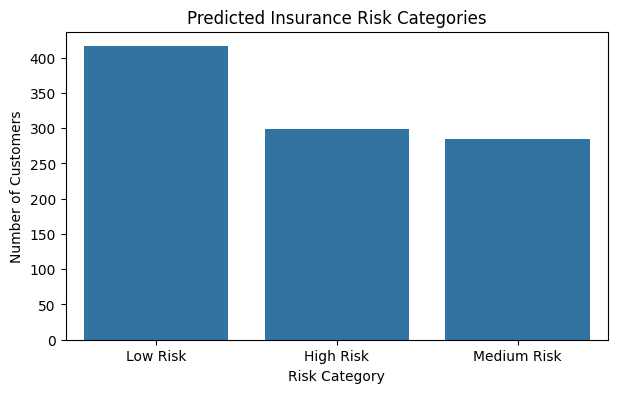

,count
Low Risk,416
High Risk,299
Medium Risk,285


In [ ]:
# Risk category distribution
risk_counts = pd.Series(risk_categories).value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=risk_counts.index, y=risk_counts.values)
plt.title("Predicted Insurance Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.show()

display(risk_counts)


## 9. Predict Risk for a New Customer

Change the values below to simulate different customer profiles.


In [ ]:
# Helper function for single-customer prediction
def prepare_new_customer(customer_dict):
    new_df = pd.DataFrame([customer_dict])

    new_df["claim_frequency"] = (
        new_df["previous_claims"] /
        new_df["policy_duration"].clip(lower=1)
    )

    new_df["hospitalization_rate"] = (
        new_df["hospital_visits"] /
        new_df["policy_duration"].clip(lower=1)
    )

    new_df["income_per_dependent"] = (
        new_df["annual_income"] /
        (new_df["dependents"] + 1)
    )

    new_df["health_risk_index"] = (
        (new_df["bmi"] > 30).astype(int)
        + (new_df["smoker"] == "Yes").astype(int)
        + (new_df["chronic_condition"] == "Yes").astype(int)
        + (new_df["hospital_visits"] >= 4).astype(int)
    )

    new_encoded = pd.get_dummies(
        new_df,
        columns=categorical_cols,
        dtype=float
    )

    new_encoded = new_encoded.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    new_encoded[numeric_feature_cols] = scaler.transform(
        new_encoded[numeric_feature_cols]
    )

    return new_encoded.astype(np.float32)


def predict_customer(customer_dict):
    prepared = prepare_new_customer(customer_dict)
    probability = float(model.predict(prepared, verbose=0)[0][0])
    score = probability * 100
    category = risk_category(score)

    return {
        "Claim Probability": probability,
        "Risk Score": score,
        "Risk Category": category
    }


new_customer = {
    "age": 52,
    "gender": "Male",
    "bmi": 32.5,
    "smoker": "Yes",
    "annual_income": 85000,
    "dependents": 2,
    "previous_claims": 4,
    "hospital_visits": 6,
    "policy_duration": 5,
    "chronic_condition": "Yes",
    "exercise_frequency": "Low",
    "alcohol_consumption": "Medium",
    "region": "North"
}

prediction = predict_customer(new_customer)

print(f"Claim Probability: {prediction['Claim Probability'] * 100:.2f}%")
print(f"Risk Score: {prediction['Risk Score']:.2f}/100")
print(f"Risk Category: {prediction['Risk Category']}")


Claim Probability: 99.83%
Risk Score: 99.83/100
Risk Category: High Risk


## 10. SHAP Explainability

SHAP helps explain which features influence individual predictions.

Because this is a neural network, we use `shap.KernelExplainer` on a small background sample. This is computationally more expensive than model-specific explainers, so the sample sizes are intentionally limited.


  0%|          | 0/10 [00:00<?, ?it/s]

/tmp/ipykernel_7142/4180518754.py:24: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


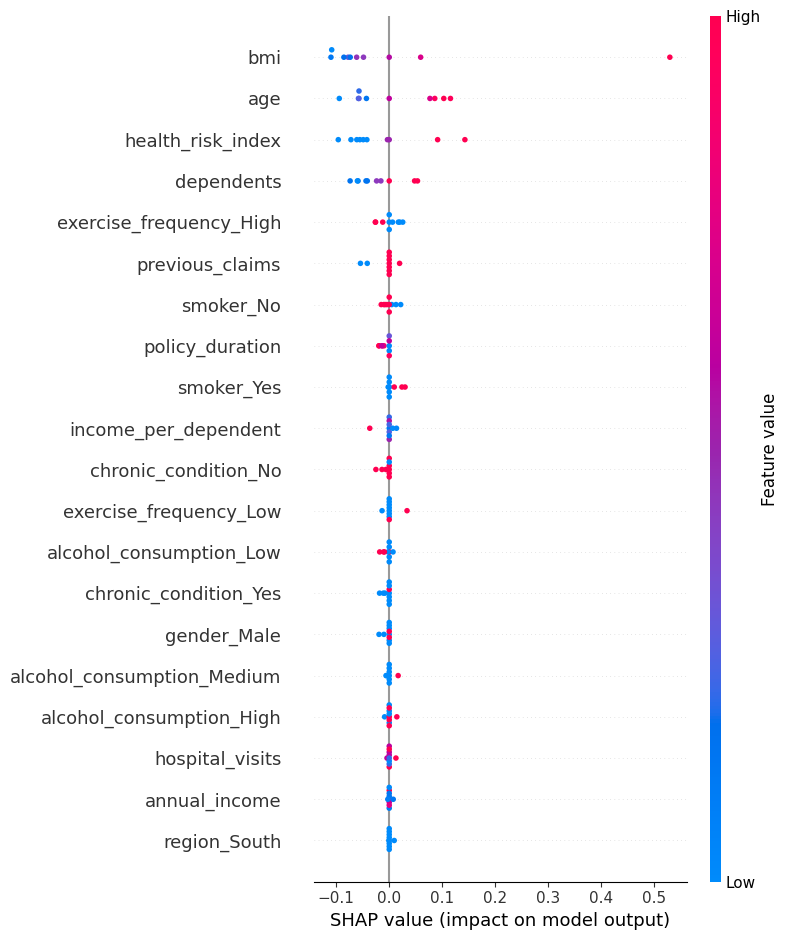

In [ ]:
# SHAP explanation on a small sample
background = X_train.sample(min(50, len(X_train)), random_state=SEED)
explain_sample = X_test.sample(min(10, len(X_test)), random_state=SEED)

explainer = shap.KernelExplainer(
    lambda x: model.predict(np.asarray(x), verbose=0).ravel(),
    background.to_numpy()
)

shap_values = explainer.shap_values(
    explain_sample.to_numpy(),
    nsamples=100
)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    shap_array = np.asarray(shap_values[0])
else:
    shap_array = np.asarray(shap_values)

if shap_array.ndim == 3:
    shap_array = shap_array[0]

shap.summary_plot(
    shap_array,
    explain_sample,
    show=True
)


,feature,mean_abs_shap
1,bmi,0.115489
0,age,0.069125
10,health_risk_index,0.061401
3,dependents,0.041902
17,exercise_frequency_High,0.013315
4,previous_claims,0.011536
13,smoker_No,0.007666
6,policy_duration,0.007570
14,smoker_Yes,0.006559
9,income_per_dependent,0.005711


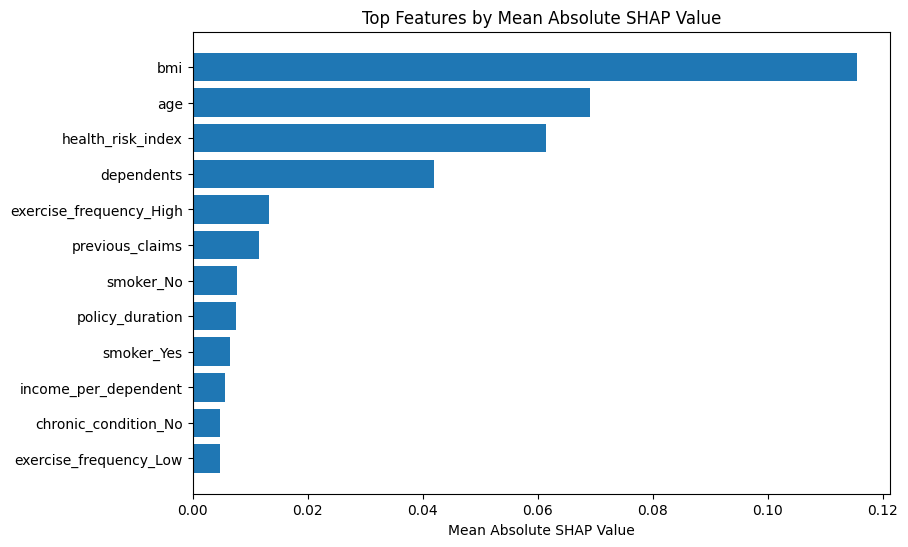

In [ ]:
# Approximate global feature importance from absolute SHAP values
mean_abs_shap = np.abs(shap_array).mean(axis=0)

importance = (
    pd.DataFrame({
        "feature": explain_sample.columns,
        "mean_abs_shap": mean_abs_shap
    })
    .sort_values("mean_abs_shap", ascending=False)
)

display(importance.head(15))

plt.figure(figsize=(9, 6))
top_imp = importance.head(12).sort_values("mean_abs_shap")
plt.barh(top_imp["feature"], top_imp["mean_abs_shap"])
plt.title("Top Features by Mean Absolute SHAP Value")
plt.xlabel("Mean Absolute SHAP Value")
plt.show()


## 11. Save the Model and Preprocessing Objects

These files can later be used by a Streamlit application or API.


In [ ]:
# Create model directory
os.makedirs("insurance_risk_model", exist_ok=True)

# Save Keras model
model_path = "insurance_risk_model/insurance_risk_model.keras"
model.save(model_path)

# Save scaler and feature metadata
joblib.dump(scaler, "insurance_risk_model/scaler.pkl")
joblib.dump(
    {
        "feature_columns": list(X_train.columns),
        "categorical_columns": categorical_cols,
        "numeric_feature_columns": numeric_feature_cols
    },
    "insurance_risk_model/feature_metadata.pkl"
)

# Save a sample risk results file
risk_results.to_csv(
    "insurance_risk_model/risk_predictions.csv",
    index=False
)

print("Saved files:")
for root, dirs, files in os.walk("insurance_risk_model"):
    for file in files:
        print(os.path.join(root, file))


Saved files:
insurance_risk_model/feature_metadata.pkl
insurance_risk_model/scaler.pkl
insurance_risk_model/risk_predictions.csv
insurance_risk_model/insurance_risk_model.keras


## 12. Download the Project Files

The next cell creates a ZIP file containing the trained model, scaler, metadata, and predictions.


In [ ]:
# Zip saved artifacts
import shutil

zip_path = shutil.make_archive(
    "insurance_risk_scoring_artifacts",
    "zip",
    "insurance_risk_model"
)

print("ZIP created:", zip_path)


ZIP created: /content/insurance_risk_scoring_artifacts.zip


In [ ]:
"""## Install Streamlit (if not already installed)
!pip install streamlit

import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from tensorflow.keras.models import load_model

# Fallback to current working directory when running interactively in Colab
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

MODEL_DIR = BASE_DIR / "insurance_risk_model"

MODEL_PATH = MODEL_DIR / "insurance_risk_model.keras"
SCALER_PATH = MODEL_DIR / "scaler.pkl"
METADATA_PATH = MODEL_DIR / "feature_metadata.pkl"

st.set_page_config(
    page_title="Insurance Risk Scoring",
    page_icon="🛡️",
    layout="wide",
)

@st.cache_resource
def load_artifacts():
    model = load_model(MODEL_PATH)
    scaler = joblib.load(SCALER_PATH)
    metadata = joblib.load(METADATA_PATH)
    return model, scaler, metadata

def risk_category(score):
    if score <= 30:
        return "Low Risk"
    elif score <= 60:
        return "Medium Risk"
    return "High Risk"

def prepare_customer(customer_dict, scaler, metadata):
    new_df = pd.DataFrame([customer_dict])

    # These engineered features match the notebook's prediction logic.
    new_df["claim_frequency"] = (
        new_df["previous_claims"] /
        new_df["policy_duration"].clip(lower=1)
    )

    new_df["hospitalization_rate"] = (
        new_df["hospital_visits"] /
        new_df["policy_duration"].clip(lower=1)
    )

    new_df["income_per_dependent"] = (
        new_df["annual_income"] /
        (new_df["dependents"] + 1)
    )

    new_df["health_risk_index"] = (
        (new_df["bmi"] > 30).astype(int)
        + (new_df["smoker"] == "Yes").astype(int)
        + (new_df["chronic_condition"] == "Yes").astype(int)
        + (new_df["hospital_visits"] >= 4).astype(int)
    )

    categorical_cols = metadata["categorical_columns"]
    numeric_cols = metadata["numeric_feature_columns"]
    feature_columns = metadata["feature_columns"]

    encoded = pd.get_dummies(
        new_df,
        columns=categorical_cols,
        dtype=float
    )

    # Exactly reproduce the training feature order.
    encoded = encoded.reindex(
        columns=feature_columns,
        fill_value=0
    )

    encoded[numeric_cols] = scaler.transform(encoded[numeric_cols])

    return encoded.astype(np.float32)

def predict_customer(customer_dict, model, scaler, metadata):
    prepared = prepare_customer(customer_dict, scaler, metadata)
    probability = float(model.predict(prepared, verbose=0)[0][0])
    score = probability * 100.0
    category = risk_category(score)
    return probability, score, category

st.title("🛡️ Insurance Risk Scoring System")
st.caption("Deep Neural Network • Claim Probability • 0–100 Risk Score")

if not all(p.exists() for p in [MODEL_PATH, SCALER_PATH, METADATA_PATH]):
    st.error(
        "Model artifacts are missing. Run the final artifact-saving cell in the "
        "notebook first so that insurance_risk_model/ contains the .keras model, "
        "scaler.pkl and feature_metadata.pkl files."
    )
    st.stop()

try:
    model, scaler, metadata = load_artifacts()
except Exception as exc:
    st.error(f"Unable to load model artifacts: {exc}")
    st.stop()

st.sidebar.header("Applicant Information")

with st.sidebar.form("risk_form"):
    age = st.number_input("Age", min_value=18, max_value=80, value=52, step=1)
    gender = st.selectbox("Gender", ["Male", "Female"])
    bmi = st.number_input("BMI", min_value=16.0, max_value=45.0, value=32.5, step=0.1)
    smoker = st.selectbox("Smoker", ["No", "Yes"])
    annual_income = st.number_input(
        "Annual Income", min_value=18000.0, max_value=250000.0,
        value=85000.0, step=1000.0
    )
    dependents = st.number_input("Dependents", min_value=0, max_value=4, value=2, step=1)
    previous_claims = st.number_input(
        "Previous Claims", min_value=0, max_value=20, value=4, step=1
    )
    hospital_visits = st.number_input(
        "Hospital Visits", min_value=0, max_value=30, value=6, step=1
    )
    policy_duration = st.number_input(
        "Policy Duration (years)", min_value=1, max_value=15, value=5, step=1
    )
    chronic_condition = st.selectbox("Chronic Condition", ["No", "Yes"])
    exercise_frequency = st.selectbox(
        "Exercise Frequency", ["Low", "Medium", "High"]
    )
    alcohol_consumption = st.selectbox(
        "Alcohol Consumption", ["Low", "Medium", "High"]
    )
    region = st.selectbox("Region", ["North", "South", "East", "West"])

    submitted = st.form_submit_button("Calculate Risk", use_container_width=True)

st.markdown("### Applicant Risk Assessment")

if submitted:
    customer = {
        "age": age,
        "gender": gender,
        "bmi": bmi,
        "smoker": smoker,
        "annual_income": annual_income,
        "dependents": dependents,
        "previous_claims": previous_claims,
        "hospital_visits": hospital_visits,
        "policy_duration": policy_duration,
        "chronic_condition": chronic_condition,
        "exercise_frequency": exercise_frequency,
        "alcohol_consumption": alcohol_consumption,
        "region": region,
    }

    try:
        probability, score, category = predict_customer(
            customer, model, scaler, metadata
        )

        col1, col2, col3 = st.columns(3)
        col1.metric("Claim Probability", f"{probability * 100:.2f}%")
        col2.metric("Risk Score", f"{score:.2f} / 100")
        col3.metric("Risk Category", category)

        st.progress(min(max(score / 100, 0.0), 1.0))

        if category == "Low Risk":
            st.success("Low Risk: the predicted claim probability is relatively low.")
        elif category == "Medium Risk":
            st.warning("Medium Risk: the applicant falls in the intermediate risk range.")
        else:
            st.error("High Risk: the predicted claim probability is relatively high.")

        st.markdown("### Derived Features")
        derived = pd.DataFrame({
            "Feature": [
                "Claim Frequency",
                "Hospitalization Rate",
                "Income per Dependent",
                "Health Risk Index",
            ],
            "Value": [
                previous_claims / max(policy_duration, 1),
                hospital_visits / max(policy_duration, 1),
                annual_income / (dependents + 1),
                int(bmi > 30) + int(smoker == "Yes")
                + int(chronic_condition == "Yes")
                + int(hospital_visits >= 4),
            ],
        })
        st.dataframe(derived, use_container_width=True, hide_index=True)

        with st.expander("Applicant Details"):
            st.json(customer)

    except Exception as exc:
        st.exception(exc)

else:
    st.info("Enter the applicant details in the sidebar and click **Calculate Risk**.")

st.divider()
st.caption(
    "Educational/portfolio project using the synthetic insurance dataset from the "
    "Deep Learning notebook. The notebook's risk thresholds are: ≤30 Low, "
    "31–60 Medium, >60 High."
)"""


'## Install Streamlit (if not already installed)\n!pip install streamlit\n\nimport streamlit as st\nimport pandas as pd\nimport numpy as np\nimport joblib\nfrom pathlib import Path\nfrom tensorflow.keras.models import load_model\n\n# Fallback to current working directory when running interactively in Colab\ntry:\n    BASE_DIR = Path(__file__).resolve().parent\nexcept NameError:\n    BASE_DIR = Path.cwd()\n\nMODEL_DIR = BASE_DIR / "insurance_risk_model"\n\nMODEL_PATH = MODEL_DIR / "insurance_risk_model.keras"\nSCALER_PATH = MODEL_DIR / "scaler.pkl"\nMETADATA_PATH = MODEL_DIR / "feature_metadata.pkl"\n\nst.set_page_config(\n    page_title="Insurance Risk Scoring",\n    page_icon="🛡️",\n    layout="wide",\n)\n\n@st.cache_resource\ndef load_artifacts():\n    model = load_model(MODEL_PATH)\n    scaler = joblib.load(SCALER_PATH)\n    metadata = joblib.load(METADATA_PATH)\n    return model, scaler, metadata\n\ndef risk_category(score):\n    if score <= 30:\n        return "Low Risk"\n    elif

### Expose the Streamlit App using ngrok
To access your Streamlit dashboard from outside this Colab notebook, we will use `pyngrok` to establish a secure tunnel to local port `8501`.

In [ ]:
!pip install -q pyngrok

import subprocess
from pyngrok import ngrok
from google.colab import userdata

# Set your ngrok authtoken.
# Replace 'YOUR_NGROK_AUTHTOKEN' with your actual token or store it in Colab's secrets manager as NGROK_AUTHTOKEN.
try:
    authtoken = userdata.get('3J6S1z7BacwwV3gAht4K1QNfBok_7RFk93PGWxDeq4V8q42Ad')
except Exception:
    authtoken = '3J6S1z7BacwwV3gAht4K1QNfBok_7RFk93PGWxDeq4V8q42Ad'

if authtoken and authtoken != '3J6S1z7BacwwV3gAht4K1QNfBok_7RFk93PGWxDeq4V8q42Ad':
    ngrok.set_auth_token(authtoken)
    print("Ngrok Authtoken configured successfully!")
else:
    print("⚠️ Please provide a valid ngrok authtoken inside Colab secrets (NGROK_AUTHTOKEN) or replace 'YOUR_NGROK_AUTHTOKEN' in the code.")

⚠️ Please provide a valid ngrok authtoken inside Colab secrets (NGROK_AUTHTOKEN) or replace 'YOUR_NGROK_AUTHTOKEN' in the code.


In [ ]:
!ngrok config add-authtoken 3J6VhmoKnnyaFdrfLfFWDpFWU8D_3AujS5azXUJB6Vq25HVWn

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
# Write the Streamlit application code to a standalone app.py file
# This copies the Streamlit script we built in the previous cell

with open('app.py', 'w') as f:
    f.write('''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from tensorflow.keras.models import load_model

BASE_DIR = Path.cwd()
MODEL_DIR = BASE_DIR / "insurance_risk_model"

MODEL_PATH = MODEL_DIR / "insurance_risk_model.keras"
SCALER_PATH = MODEL_DIR / "scaler.pkl"
METADATA_PATH = MODEL_DIR / "feature_metadata.pkl"

st.set_page_config(
    page_title="Insurance Risk Scoring",
    page_icon="🛡️",
    layout="wide",
)

@st.cache_resource
def load_artifacts():
    model = load_model(MODEL_PATH)
    scaler = joblib.load(SCALER_PATH)
    metadata = joblib.load(METADATA_PATH)
    return model, scaler, metadata

def risk_category(score):
    if score <= 30:
        return "Low Risk"
    elif score <= 60:
        return "Medium Risk"
    return "High Risk"

def prepare_customer(customer_dict, scaler, metadata):
    new_df = pd.DataFrame([customer_dict])
    new_df["claim_frequency"] = (new_df["previous_claims"] / new_df["policy_duration"].clip(lower=1))
    new_df["hospitalization_rate"] = (new_df["hospital_visits"] / new_df["policy_duration"].clip(lower=1))
    new_df["income_per_dependent"] = (new_df["annual_income"] / (new_df["dependents"] + 1))
    new_df["health_risk_index"] = (
        (new_df["bmi"] > 30).astype(int)
        + (new_df["smoker"] == "Yes").astype(int)
        + (new_df["chronic_condition"] == "Yes").astype(int)
        + (new_df["hospital_visits"] >= 4).astype(int)
    )
    categorical_cols = metadata["categorical_columns"]
    numeric_cols = metadata["numeric_feature_columns"]
    feature_columns = metadata["feature_columns"]
    encoded = pd.get_dummies(new_df, columns=categorical_cols, dtype=float)
    encoded = encoded.reindex(columns=feature_columns, fill_value=0)
    encoded[numeric_cols] = scaler.transform(encoded[numeric_cols])
    return encoded.astype(np.float32)

def predict_customer(customer_dict, model, scaler, metadata):
    prepared = prepare_customer(customer_dict, scaler, metadata)
    probability = float(model.predict(prepared, verbose=0)[0][0])
    score = probability * 100.0
    category = risk_category(score)
    return probability, score, category

st.title("🛡️ Insurance Risk Scoring System")

try:
    model, scaler, metadata = load_artifacts()
except Exception as exc:
    st.error(f"Unable to load model artifacts: {exc}")
    st.stop()

st.sidebar.header("Applicant Information")
with st.sidebar.form("risk_form"):
    age = st.number_input("Age", min_value=18, max_value=80, value=52, step=1)
    gender = st.selectbox("Gender", ["Male", "Female"])
    bmi = st.number_input("BMI", min_value=16.0, max_value=45.0, value=32.5, step=0.1)
    smoker = st.selectbox("Smoker", ["No", "Yes"])
    annual_income = st.number_input("Annual Income", min_value=18000.0, max_value=250000.0, value=85000.0, step=1000.0)
    dependents = st.number_input("Dependents", min_value=0, max_value=4, value=2, step=1)
    previous_claims = st.number_input("Previous Claims", min_value=0, max_value=20, value=4, step=1)
    hospital_visits = st.number_input("Hospital Visits", min_value=0, max_value=30, value=6, step=1)
    policy_duration = st.number_input("Policy Duration (years)", min_value=1, max_value=15, value=5, step=1)
    chronic_condition = st.selectbox("Chronic Condition", ["No", "Yes"])
    exercise_frequency = st.selectbox("Exercise Frequency", ["Low", "Medium", "High"])
    alcohol_consumption = st.selectbox("Alcohol Consumption", ["Low", "Medium", "High"])
    region = st.selectbox("Region", ["North", "South", "East", "West"])
    submitted = st.form_submit_button("Calculate Risk", use_container_width=True)

if submitted:
    customer = {
        "age": age, "gender": gender, "bmi": bmi, "smoker": smoker, "annual_income": annual_income,
        "dependents": dependents, "previous_claims": previous_claims, "hospital_visits": hospital_visits,
        "policy_duration": policy_duration, "chronic_condition": chronic_condition,
        "exercise_frequency": exercise_frequency, "alcohol_consumption": alcohol_consumption, "region": region
    }
    probability, score, category = predict_customer(customer, model, scaler, metadata)
    col1, col2, col3 = st.columns(3)
    col1.metric("Claim Probability", f"{probability * 100:.2f}%")
    col2.metric("Risk Score", f"{score:.2f} / 100")
    col3.metric("Risk Category", category)
    st.progress(score / 100.0)
else:
    st.info("Enter applicant details in the sidebar to calculate risk.")
''')

In [ ]:
# Start Streamlit background server on local port 8501
import subprocess
import sys
from pyngrok import ngrok, exception

# Ensure streamlit is installed
try:
    import streamlit
except ImportError:
    print("Installing streamlit...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit"])

try:
    # Kill any existing ngrok tunnels
    ngrok.kill()
except:
    pass

# Launch the Streamlit application in the background using python -m streamlit to prevent executable path issues
streamlit_process = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501"])

try:
    # Attempt to establish an ngrok tunnel to local port 8501
    public_url = ngrok.connect(addr="8501", proto="http")
    print(f"🔥 Streamlit app is live at: {public_url}")
except exception.PyngrokNgrokError as e:
    print("❌ Ngrok Tunnel connection failed!")
    print("This error usually happens because a valid Ngrok Authtoken was not provided.")
    print("\nHow to fix this:")
    print("1. Sign up for free at: https://dashboard.ngrok.com/signup")
    print("2. Retrieve your authtoken from: https://dashboard.ngrok.com/get-started/your-authtoken")
    print("3. Go to the Colab Secrets tab (the key icon on the left menu 🔑) and add your token with the name NGROK_AUTHTOKEN.")
    print("   (Alternatively, replace the placeholder token in cell '78a6d34a' with your token and run it first.)")

❌ Ngrok Tunnel connection failed!
This error usually happens because a valid Ngrok Authtoken was not provided.

How to fix this:
1. Sign up for free at: https://dashboard.ngrok.com/signup
2. Retrieve your authtoken from: https://dashboard.ngrok.com/get-started/your-authtoken
3. Go to the Colab Secrets tab (the key icon on the left menu 🔑) and add your token with the name NGROK_AUTHTOKEN.
   (Alternatively, replace the placeholder token in cell '78a6d34a' with your token and run it first.)


In [ ]:
import os
import sys

print("Restarting Colab runtime to clear active ngrok processes and release ports...")
# Terminate the current process to trigger an automatic runtime restart
os.kill(os.getpid(), 9)

# Project Summary

### Input
Customer demographic, financial, health/lifestyle, policy, and claims-related features.

### Deep Learning
A fully connected neural network learns nonlinear relationships among the features.

### Output
- Claim probability
- Risk score from 0 to 100
- Low / Medium / High risk category

### Explainability
SHAP identifies influential features behind model predictions.

### Next step
The saved `.keras` model and `.pkl` preprocessing files can be integrated into a **Streamlit insurance risk scoring dashboard**.
